# Supplementary figures for the reviewer response

Figures S4 to S8 for Reviewer 1 comment 5 and Reviewer 2. Run from the top. Each figure is saved as EPS and TIFF (300 dpi) in `supplementary_figures/`.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
TRANSCELL_RESULTS = f'{DATA_DIR}/ALLDECONVALID_results.csv'
DRUG_AUC = f'{DATA_DIR}/beataml2_patients_drug.csv'
CLINICAL = f'{DATA_DIR}/beataml2_data.csv'

In [1]:
out = FIGURE_DIR
os.makedirs(out, exist_ok=True)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
    'axes.linewidth': 0.6,
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'ps.fonttype': 42,
    'pdf.fonttype': 42,
})
blue, orange, grey = '#1f4e79', '#d4760a', '#8c8c8c'
censor = {'ms': 3, 'mew': 0.6, 'marker': '|'}

In [2]:
total_df = pd.read_csv(TRANSCELL_RESULTS, index_col=0)
drug_file = pd.read_csv(DRUG_AUC, usecols=['dbgap_subject_id', 'inhibitor', 'auc'])
clin_raw = pd.read_csv(CLINICAL, low_memory=False)

In [3]:
# 7+3 cohort: de novo, RNA-seq, specimen at inclusion, 7+3-type induction (anthracycline + cytarabine)
clin = clin_raw[(clin_raw['rnaSeq'] == 'y') & (clin_raw['isDenovo'].astype(str).str.upper() == 'TRUE')
                & (clin_raw['timeOfSampleCollectionRelativeToInclusion'] == 0)
                & (clin_raw['typeInductionTx'] == 'Standard Chemotherapy')]
clin = clin[clin['cumulativeTreatmentRegimens'].str.split('|').str[0].str.contains(r'^(?:7\+3|5\+2|3\+7)', na=False)]
clin = clin[clin['vitalStatus'].isin(['Dead', 'Alive']) & (clin['overallSurvival'] > 0)]
clin = clin.drop_duplicates('dbgap_subject_id').set_index('dbgap_subject_id').copy()

clin['E'] = (clin['vitalStatus'] == 'Dead').astype(int)
clin['years'] = clin['overallSurvival'] / 365.25
clin['eln'] = clin['ELN2017'].map({'Favorable': 0, 'Intermediate': 1, 'Adverse': 2})
clin['remission'] = clin['responseToInductionTx'].map({
    'Complete Response': 'Remission', 'Complete Response i': 'Remission', 'Refractory': 'Refractory'})
clin['blast'] = pd.to_numeric(clin['%.Blasts.in.BM'], errors='coerce')
clin['blast_group'] = pd.Series(index=clin.index, dtype='object')
clin.loc[clin['blast'] < 50, 'blast_group'] = 'low'
clin.loc[clin['blast'] > 50, 'blast_group'] = 'high'

cohort = clin[['overallSurvival', 'years', 'E', 'ageAtDiagnosis', 'eln', 'remission', 'blast_group']]
print(len(cohort), 'patients,', int(cohort.E.sum()), 'deaths')

130 patients, 61 deaths


In [4]:
list_refs = ['P38', 'P14', 'P30', 'P23', 'P34', 'P25', 'P20', 'P36']
methods = ['Bulk'] + list_refs
drugs = ['cytarabine', 'daunorubicin', 'idarubicin', 'venetoclax', 'azacitidine']

scores = {}
for drug in drugs:
    one = total_df.loc[drug]
    wide = DataFrame({'ref': one.index.str.split('_').str[0],
                      'pid': one.index.str.split('_').str[1].astype(int),
                      'v': one.values}).pivot_table(index='pid', columns='ref', values='v')
    scores[drug] = wide.reindex(columns=methods).reindex(cohort.index)
    print(drug, int(scores[drug]['Bulk'].notna().sum()), 'patients with scores')

cytarabine 78 patients with scores
daunorubicin 78 patients with scores
idarubicin 78 patients with scores
venetoclax 78 patients with scores
azacitidine 78 patients with scores


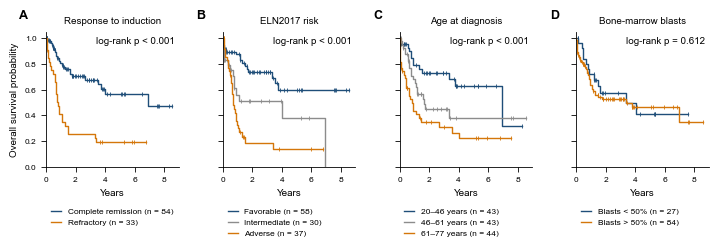

In [5]:
# Figure S4. Overall survival by clinical variables. No TransCell score is used.
d1 = cohort.dropna(subset=['remission']).copy()
d1['g'] = d1.remission
d2 = cohort.dropna(subset=['eln']).copy()
d2['g'] = d2.eln.map({0: 'Favorable', 1: 'Intermediate', 2: 'Adverse'})
d3 = cohort.dropna(subset=['ageAtDiagnosis']).copy()
d3['g'] = pd.qcut(d3.ageAtDiagnosis.rank(method='first'), 3, labels=['younger', 'middle', 'older']).astype(str)
ages = d3.groupby('g').ageAtDiagnosis.agg(['min', 'max']).loc[['younger', 'middle', 'older']]
age_labels = [f'{lo:.0f}–{hi:.0f} years' for lo, hi in zip(ages['min'], ages['max'])]
d4 = cohort.dropna(subset=['blast_group']).copy()
d4['g'] = d4.blast_group

panels = [
    ('Response to induction', d1, [('Remission', 'Complete remission', blue), ('Refractory', 'Refractory', orange)]),
    ('ELN2017 risk', d2, [('Favorable', 'Favorable', blue), ('Intermediate', 'Intermediate', grey), ('Adverse', 'Adverse', orange)]),
    ('Age at diagnosis', d3, list(zip(['younger', 'middle', 'older'], age_labels, [blue, grey, orange]))),
    ('Bone-marrow blasts', d4, [('low', 'Blasts < 50%', blue), ('high', 'Blasts > 50%', orange)]),
]

fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.8), sharey=True)
for ax, letter, (title, d, groups) in zip(axes, 'ABCD', panels):
    kmf = KaplanMeierFitter()
    for g, label, color in groups:
        sub = d[d.g == g]
        kmf.fit(sub.years, sub.E, label=f'{label} (n = {len(sub)})')
        kmf.plot_survival_function(ax=ax, ci_show=False, color=color, lw=1, show_censors=True, censor_styles=censor)
    if len(groups) == 2:
        a = d[d.g == groups[0][0]]
        b = d[d.g == groups[1][0]]
        p = logrank_test(a.years, b.years, a.E, b.E).p_value
    else:
        p = multivariate_logrank_test(d.years, d.g, d.E).p_value
    ax.text(0.97, 0.97, 'log-rank p < 0.001' if p < 0.001 else f'log-rank p = {p:.3f}',
            transform=ax.transAxes, ha='right', va='top')
    ax.text(-0.2, 1.1, letter, transform=ax.transAxes, fontsize=9, fontweight='bold')
    ax.set_title(title)
    ax.set_xlabel('Years')
    ax.set_ylabel('')
    ax.set_ylim(0, 1.05)
    ax.set_xlim(left=0)
    ax.legend(loc='upper left', bbox_to_anchor=(-0.02, -0.25), frameon=False, handlelength=1.2)
axes[0].set_ylabel('Overall survival probability')
plt.tight_layout()
fig.savefig(f'{out}/Figure S4.eps')
fig.savefig(f'{out}/Figure S4.tif', dpi=300)
plt.show()

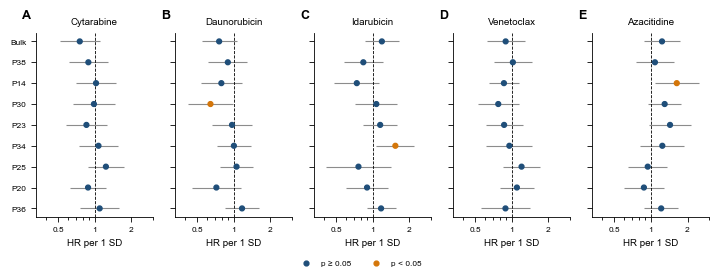

        drug method  n  deaths    HR    lo    hi     p  q_BH
  cytarabine   Bulk 73      32 0.754 0.518 1.098 0.141 0.732
  cytarabine    P38 73      32 0.887 0.615 1.279 0.520 0.813
  cytarabine    P14 73      32 1.025 0.707 1.487 0.897 0.953
  cytarabine    P30 73      32 0.985 0.664 1.462 0.940 0.962
  cytarabine    P23 73      32 0.855 0.583 1.253 0.422 0.760
  cytarabine    P34 73      32 1.074 0.737 1.563 0.711 0.874
  cytarabine    P25 73      32 1.235 0.880 1.734 0.223 0.732
  cytarabine    P20 73      32 0.882 0.626 1.242 0.472 0.813
  cytarabine    P36 73      32 1.098 0.758 1.590 0.622 0.823
daunorubicin   Bulk 73      32 0.759 0.546 1.055 0.101 0.732
daunorubicin    P38 73      32 0.894 0.620 1.291 0.552 0.813
daunorubicin    P14 73      32 0.792 0.535 1.172 0.243 0.732
daunorubicin    P30 73      32 0.644 0.418 0.993 0.046 0.695
daunorubicin    P23 73      32 0.968 0.659 1.422 0.869 0.953
daunorubicin    P34 73      32 1.003 0.725 1.387 0.986 0.986
daunorubicin    P25 73  

In [6]:
# Figure S5. Cox HR per 1 SD of TransCell score, adjusted for age and ELN2017.
# HR above 1 means a higher score (less predicted sensitivity) goes with a higher risk of death.
rows = []
for drug in drugs:
    for m in methods:
        d = cohort.join(scores[drug][m].rename('score')).dropna(subset=['score', 'ageAtDiagnosis', 'eln']).copy()
        d['z'] = (d.score - d.score.mean()) / d.score.std()
        cph = CoxPHFitter().fit(d[['overallSurvival', 'E', 'z', 'ageAtDiagnosis', 'eln']], 'overallSurvival', 'E')
        s = cph.summary.loc['z']
        rows.append([drug, m, len(d), int(d.E.sum()), s['exp(coef)'], s['exp(coef) lower 95%'], s['exp(coef) upper 95%'], s['p']])
cox_df = DataFrame(rows, columns=['drug', 'method', 'n', 'deaths', 'HR', 'lo', 'hi', 'p'])
order = np.argsort(cox_df.p.values)
ranked = cox_df.p.values[order] * len(cox_df) / np.arange(1, len(cox_df) + 1)
cox_df.loc[cox_df.index[order], 'q_BH'] = np.minimum(np.minimum.accumulate(ranked[::-1])[::-1], 1)

fig, axes = plt.subplots(1, len(drugs), figsize=(7.2, 2.6), sharey=True)
y = np.arange(len(methods))[::-1]
for ax, letter, drug in zip(axes, 'ABCDE', drugs):
    d = cox_df[cox_df.drug == drug].set_index('method').loc[methods]
    ax.hlines(y, d.lo, d.hi, color=grey, lw=0.8)
    ax.scatter(d.HR, y, c=[orange if p < 0.05 else blue for p in d.p], s=12, zorder=3)
    ax.axvline(1, color='black', lw=0.6, ls='--')
    ax.set_xscale('log')
    ax.set_xticks([0.5, 1, 2])
    ax.set_xticklabels(['0.5', '1', '2'])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlim(0.33, 3)
    ax.set_title(drug.capitalize())
    ax.set_xlabel('HR per 1 SD')
    ax.text(-0.12, 1.08, letter, transform=ax.transAxes, fontsize=9, fontweight='bold')
axes[0].set_yticks(y)
axes[0].set_yticklabels(methods)
axes[-1].scatter([], [], c=blue, s=12, label='p ≥ 0.05')
axes[-1].scatter([], [], c=orange, s=12, label='p < 0.05')
plt.tight_layout()
fig.legend(*axes[-1].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False)
fig.savefig(f'{out}/Figure S5.eps')
fig.savefig(f'{out}/Figure S5.tif', dpi=300)
plt.show()

print(cox_df.round(3).to_string(index=False))

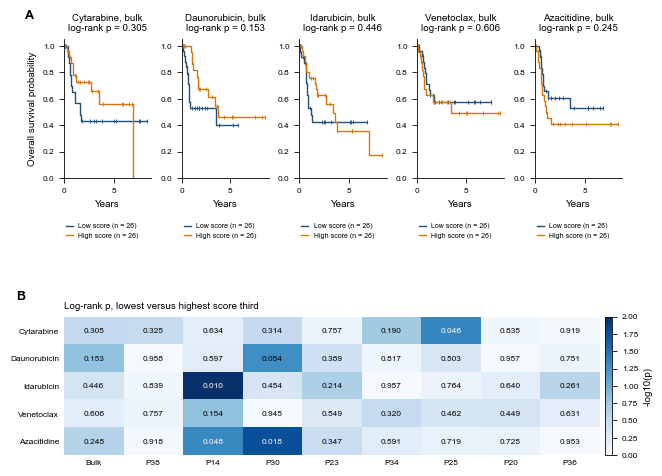

        drug method  n_low  n_high     p
  cytarabine   Bulk     26      26 0.305
  cytarabine    P38     26      26 0.325
  cytarabine    P14     26      26 0.634
  cytarabine    P30     26      26 0.314
  cytarabine    P23     26      26 0.757
  cytarabine    P34     26      26 0.190
  cytarabine    P25     26      26 0.046
  cytarabine    P20     26      26 0.835
  cytarabine    P36     26      26 0.919
daunorubicin   Bulk     26      26 0.153
daunorubicin    P38     26      26 0.958
daunorubicin    P14     26      26 0.597
daunorubicin    P30     26      26 0.054
daunorubicin    P23     26      26 0.389
daunorubicin    P34     26      26 0.817
daunorubicin    P25     26      26 0.503
daunorubicin    P20     26      26 0.957
daunorubicin    P36     26      26 0.751
  idarubicin   Bulk     26      26 0.446
  idarubicin    P38     26      26 0.839
  idarubicin    P14     26      26 0.010
  idarubicin    P30     26      26 0.454
  idarubicin    P23     26      26 0.214
  idarubicin    

In [7]:
# Figure S6. Overall survival by TransCell score: lowest versus highest third of patients.
lr_rows = []
for drug in drugs:
    for m in methods:
        d = cohort.join(scores[drug][m].rename('score')).dropna(subset=['score']).copy()
        d['band'] = pd.qcut(d.score.rank(method='first'), 3, labels=['low', 'middle', 'high'])
        low = d[d.band == 'low']
        high = d[d.band == 'high']
        p = logrank_test(high.years, low.years, high.E, low.E).p_value
        lr_rows.append([drug, m, len(low), len(high), p])
lr_df = DataFrame(lr_rows, columns=['drug', 'method', 'n_low', 'n_high', 'p'])

fig = plt.figure(figsize=(7.2, 5.4))
gs = fig.add_gridspec(2, 5, hspace=1.0, wspace=0.35)
for i, drug in enumerate(drugs):
    ax = fig.add_subplot(gs[0, i])
    d = cohort.join(scores[drug]['Bulk'].rename('score')).dropna(subset=['score']).copy()
    d['band'] = pd.qcut(d.score.rank(method='first'), 3, labels=['low', 'middle', 'high'])
    kmf = KaplanMeierFitter()
    for band, label, color in [('low', 'Low score', blue), ('high', 'High score', orange)]:
        sub = d[d.band == band]
        kmf.fit(sub.years, sub.E, label=f'{label} (n = {len(sub)})')
        kmf.plot_survival_function(ax=ax, ci_show=False, color=color, lw=1, show_censors=True, censor_styles=censor)
    p = lr_df[(lr_df.drug == drug) & (lr_df.method == 'Bulk')].p.iloc[0]
    ax.set_title(f'{drug.capitalize()}, bulk\nlog-rank p = {p:.3f}')
    ax.set_xlabel('Years')
    ax.set_ylabel('Overall survival probability' if i == 0 else '')
    ax.set_ylim(0, 1.05)
    ax.set_xlim(left=0)
    ax.legend(loc='upper left', bbox_to_anchor=(-0.05, -0.28), frameon=False, fontsize=5, handlelength=1)
    if i == 0:
        ax.text(-0.45, 1.15, 'A', transform=ax.transAxes, fontsize=9, fontweight='bold')

ax = fig.add_subplot(gs[1, :])
mat = lr_df.pivot(index='drug', columns='method', values='p').loc[drugs, methods]
im = ax.imshow(-np.log10(mat.values), cmap='Blues', vmin=0, vmax=2, aspect='auto')
for r in range(len(drugs)):
    for c in range(len(methods)):
        v = mat.values[r, c]
        ax.text(c, r, f'{v:.3f}', ha='center', va='center', fontsize=6,
                color='white' if v < 0.05 else 'black')
ax.set_xticks(range(len(methods)))
ax.set_xticklabels(methods)
ax.set_yticks(range(len(drugs)))
ax.set_yticklabels([drug.capitalize() for drug in drugs])
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title('Log-rank p, lowest versus highest score third', loc='left')
ax.text(-0.09, 1.12, 'B', transform=ax.transAxes, fontsize=9, fontweight='bold')
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
cbar.set_label('-log10(p)')
cbar.outline.set_linewidth(0.6)
fig.savefig(f'{out}/Figure S6.eps')
fig.savefig(f'{out}/Figure S6.tif', dpi=300)
plt.show()

print(lr_df.round(3).to_string(index=False))

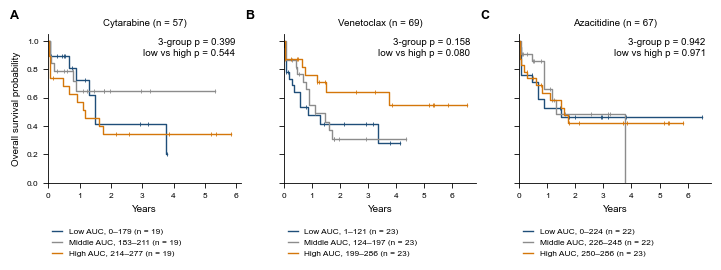

       drug  n_km  deaths  logrank_3grp_p  logrank_low_high_p  n_cox  HR_per_SD    lo    hi  cox_p
 cytarabine    57      26           0.399               0.544     56      1.130 0.716 1.783  0.600
 venetoclax    69      34           0.158               0.080     67      0.688 0.481 0.984  0.041
azacitidine    67      31           0.942               0.971     64      0.967 0.629 1.486  0.877


In [8]:
# Figure S7. Overall survival by measured ex vivo AUC. Higher AUC means less sensitive.
# Daunorubicin and idarubicin are not in the Beat AML ex vivo panel.
auc_name = {'cytarabine': 'Cytarabine', 'venetoclax': 'Venetoclax', 'azacitidine': 'Azacytidine'}
auc_rows = []
fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.0), sharey=True)
for ax, letter, drug in zip(axes, 'ABC', auc_name):
    auc = drug_file[drug_file.inhibitor == auc_name[drug]].groupby('dbgap_subject_id').auc.mean()
    d = cohort.join(auc.rename('auc')).dropna(subset=['auc']).copy()
    d['band'] = pd.qcut(d.auc.rank(method='first'), 3, labels=['low', 'middle', 'high'])
    kmf = KaplanMeierFitter()
    for band, label, color in [('low', 'Low AUC', blue), ('middle', 'Middle AUC', grey), ('high', 'High AUC', orange)]:
        sub = d[d.band == band]
        kmf.fit(sub.years, sub.E, label=f'{label}, {sub.auc.min():.0f}–{sub.auc.max():.0f} (n = {len(sub)})')
        kmf.plot_survival_function(ax=ax, ci_show=False, color=color, lw=1, show_censors=True, censor_styles=censor)
    p3 = multivariate_logrank_test(d.years, d.band, d.E).p_value
    low = d[d.band == 'low']
    high = d[d.band == 'high']
    p2 = logrank_test(high.years, low.years, high.E, low.E).p_value
    fit = d.dropna(subset=['ageAtDiagnosis', 'eln']).copy()
    fit['z'] = (fit.auc - fit.auc.mean()) / fit.auc.std()
    cph = CoxPHFitter().fit(fit[['overallSurvival', 'E', 'z', 'ageAtDiagnosis', 'eln']], 'overallSurvival', 'E')
    s = cph.summary.loc['z']
    auc_rows.append([drug, len(d), int(d.E.sum()), p3, p2, len(fit), s['exp(coef)'], s['exp(coef) lower 95%'], s['exp(coef) upper 95%'], s['p']])
    ax.text(0.97, 0.97, f'3-group p = {p3:.3f}\nlow vs high p = {p2:.3f}', transform=ax.transAxes, ha='right', va='top')
    ax.text(-0.2, 1.1, letter, transform=ax.transAxes, fontsize=9, fontweight='bold')
    ax.set_title(f'{drug.capitalize()} (n = {len(d)})')
    ax.set_xlabel('Years')
    ax.set_ylabel('')
    ax.set_ylim(0, 1.05)
    ax.set_xlim(left=0)
    ax.legend(loc='upper left', bbox_to_anchor=(-0.02, -0.25), frameon=False, fontsize=6, handlelength=1.2)
axes[0].set_ylabel('Overall survival probability')
plt.tight_layout()
fig.savefig(f'{out}/Figure S7.eps')
fig.savefig(f'{out}/Figure S7.tif', dpi=300)
plt.show()

auc_df = DataFrame(auc_rows, columns=['drug', 'n_km', 'deaths', 'logrank_3grp_p', 'logrank_low_high_p', 'n_cox', 'HR_per_SD', 'lo', 'hi', 'cox_p'])
print(auc_df.round(3).to_string(index=False))